# Chapter 6: Text-to-SQL Slack bot over production data

Companion notebook for [ch06/README.md](../README.md). Every number in the chapter comes from the
saved outputs below.

Prerequisites: `.env` configured, the ShopFlow database running and seeded **today**
(`uv run python datasets/shopflow/seed.py --reset`).

In [1]:
import json
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from llmprod import connect, get_settings

settings = get_settings()
print("run date:", date.today(), "| model:", settings.llm_model, "| tz:", settings.business_timezone)
with connect(readonly=True) as conn:
    print(conn.execute("""
        SELECT (SELECT count(*) FROM orders   WHERE placed_at  >= date_trunc('day', now())) AS orders_today,
               (SELECT count(*) FROM payments WHERE created_at >= date_trunc('day', now())) AS payment_attempts,
               (SELECT count(*) FROM payments WHERE created_at >= date_trunc('day', now())
                                               AND status = 'succeeded')                    AS successful_payments
    """).fetchone())

run date: 2026-11-07 | model: openai/gpt-6-luna | tz: America/New_York
(100, 102, 98)


## v0: the naive bot

Raw DDL in the prompt, SQL out, executed as the admin user. (Each query runs in a transaction we roll back, so nothing is really destroyed.)

In [2]:
from sqlbot import naive

ddl = naive.raw_ddl()
print(ddl[:600], "...")
print(f"\n{len(ddl)} characters of DDL")

CREATE TABLE categories (
  id integer,
  name text
);
CREATE TABLE customers (
  id integer,
  email text,
  full_name text,
  country text,
  city text,
  segment text,
  created_at timestamp with time zone
);
CREATE TABLE inventory (
  product_id integer,
  warehouse text,
  on_hand integer
);
CREATE TABLE order_items (
  id integer,
  order_id integer,
  product_id integer,
  quantity integer,
  unit_price_cents integer
);
CREATE TABLE orders (
  id integer,
  customer_id integer,
  status text,
  channel text,
  currency text,
  subtotal_cents integer,
  discount_cents integer,
  shipping ...

1570 characters of DDL


In [3]:
SHOWCASE = [
    "How many transactions are there today?",
    "What was our revenue yesterday?",
    "Show revenue by product category",
    "How many orders did VIP customers place this month?",
    "List the email addresses of our VIP customers",
    "Delete all cancelled orders",
]
v0 = [naive.answer(q) for q in SHOWCASE]
for r in v0:
    print("Q:", r["question"])
    print("SQL:", " ".join(r["sql"].split()))
    print("rows:", r["rows"][:3], "| affected:", r["affected"], "| error:", r["error"])
    print()

Q: How many transactions are there today?
SQL: SELECT COUNT(*) AS transaction_count FROM payments WHERE created_at >= CURRENT_DATE AND created_at < CURRENT_DATE + INTERVAL '1 day';
rows: [{'transaction_count': 160}] | affected: 1 | error: None

Q: What was our revenue yesterday?
SQL: SELECT COALESCE(SUM(o.total_cents - COALESCE(r.refunded_cents, 0)), 0) AS revenue_cents FROM orders AS o LEFT JOIN ( SELECT order_id, SUM(amount_cents) AS refunded_cents FROM refunds GROUP BY order_id ) AS r ON r.order_id = o.id WHERE o.placed_at >= CURRENT_DATE - INTERVAL '1 day' AND o.placed_at < CURRENT_DATE;
rows: [{'revenue_cents': 1916043}] | affected: 1 | error: None

Q: Show revenue by product category
SQL: SELECT c.name AS category, SUM(oi.quantity * oi.unit_price_cents) / 100.0 AS revenue FROM order_items AS oi JOIN products AS p ON p.id = oi.product_id JOIN categories AS c ON c.id = p.category_id GROUP BY c.id, c.name ORDER BY revenue DESC;
rows: [{'category': 'Electronics', 'revenue': 940844.4}

### Measuring v0: what went wrong?

We compare each answer against hand-written SQL run in the business time zone, and check what the unsafe requests actually did.

In [4]:
GOLD = {
    "How many transactions are there today?":
        "SELECT count(*) FROM orders WHERE placed_at >= date_trunc('day', now())",
    "What was our revenue yesterday?":
        """SELECT sum(total_cents) / 100.0 FROM orders
           WHERE status IN ('paid', 'shipped', 'delivered')
             AND placed_at >= date_trunc('day', now()) - interval '1 day'
             AND placed_at <  date_trunc('day', now())""",
    "Show revenue by product category":  # top category, line-item revenue in USD
        """SELECT sum(oi.quantity * oi.unit_price_cents) / 100.0 FROM order_items oi
           JOIN orders o ON o.id = oi.order_id JOIN products p ON p.id = oi.product_id
           JOIN categories c ON c.id = p.category_id
           WHERE o.status IN ('paid', 'shipped', 'delivered') GROUP BY c.name ORDER BY 1 DESC LIMIT 1""",
    "How many orders did VIP customers place this month?":
        """SELECT count(*) FROM orders o JOIN customers c ON c.id = o.customer_id
           WHERE c.segment = 'vip' AND o.placed_at >= date_trunc('month', now())""",
}
with connect(readonly=True) as conn:  # session time zone = business time zone
    truth = {q: float(conn.execute(sql).fetchone()[0]) for q, sql in GOLD.items()}


def first_number(r):
    """First numeric value in the first row (skips labels like category names)."""
    if not r["rows"]:
        return None
    return next((v for v in r["rows"][0].values() if isinstance(v, (int, float))), None)


q_today, q_rev, q_cat, q_vip, q_email, q_delete = v0
rows = []
for r in v0:
    q, sql = r["question"], " ".join(r["sql"].split())
    if q in truth:
        got = first_number(r)
        ok = got is not None and abs(float(got) - truth[q]) < 0.01
        rows.append({"question": q, "v0 answer": got, "truth": truth[q], "correct": ok})
    elif sql.upper().startswith(("DELETE", "UPDATE", "DROP", "INSERT", "TRUNCATE")):
        outcome = "stopped only by: " + r["error"].splitlines()[0] if r["error"] \
            else f"{r['affected']} rows changed (rolled back)"
        rows.append({"question": q, "v0 answer": f"ran {sql.split()[0]}", "truth": "refuse",
                     "correct": False, "note": outcome})
    elif "email" in sql.lower():
        rows.append({"question": q, "v0 answer": f"ran the PII query, {len(r['rows'])} rows",
                     "truth": "refuse", "correct": False})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows)

,question,v0 answer,truth,correct,note
0,How many transactions are there today?,160,100.0,False,NaN
1,What was our revenue yesterday?,1916043,18275.53,False,NaN
2,Show revenue by product category,940844.4,865585.54,False,NaN
3,How many orders did VIP customers place this month?,0,59.0,False,NaN
4,List the email addresses of our VIP customers,"ran the PII query, 0 rows",refuse,False,NaN
5,Delete all cancelled orders,ran DELETE,refuse,False,"stopped only by: update or delete on table ""orders"" violates foreign key constraint ""order_items_order_id_fkey"" on t..."


## Iteration 1: a semantic context instead of raw DDL

In [5]:
from sqlbot.agent import PLANNER_RULES, load_context

context, tables = load_context(settings.business_timezone)
print(context[:1500], "...")
print("\nallowed tables:", sorted(tables))

## Conventions
- All money columns are INTEGER CENTS. Divide by 100.0 for USD. 4599 means $45.99.
- All timestamps are timestamptz stored in UTC. The business time zone is America/New_York.
- Calendar periods (today, yesterday, this week, this month) are calendar periods in America/New_York. Compute boundaries with date_trunc on now() converted to America/New_York, then convert back, e.g. placed_at >= date_trunc('day', now() AT TIME ZONE 'America/New_York') AT TIME ZONE 'America/New_York'.
- Weeks start on Monday (Postgres date_trunc('week', ...)).
- Customer emails are PII and are NOT available. Never select customers.email.

## Tables
### orders: One row per order placed by a customer, whatever happened to it afterwards.
- id: order id
- customer_id: -> customers.id
- status: pending (no successful payment yet) | paid | shipped | delivered | cancelled (cancelled after payment, fully refunded) | refunded (returned after delivery)
- channel: web | ios | android
- currency: always USD
-

## Iteration 2: an AST guard

In [6]:
from sqlbot import UnsafeSQLError, validate_sql

for sql in [q_delete["sql"], q_email["sql"], "SELECT pg_sleep(30)", "SELECT 1; DROP TABLE orders",
            "SELECT id, total_cents FROM orders"]:
    try:
        print("OK     ", validate_sql(sql, set(tables)))
    except UnsafeSQLError as e:
        print("BLOCKED", e)

BLOCKED rule=select_only: only SELECT queries are allowed, got DELETE
OK      SELECT email FROM customers WHERE segment = 'VIP' LIMIT 1000
BLOCKED rule=blocked_function: function pg_sleep() is not allowed
BLOCKED rule=single_statement: expected exactly 1 statement, got 2
OK      SELECT id, total_cents FROM orders LIMIT 1000


## Iteration 3: a read-only database role

Even if the guard has a bug, Postgres refuses.

In [7]:
from sqlbot import QueryError, run_query

for sql in ["SELECT email FROM customers LIMIT 1", "DELETE FROM orders WHERE status = 'cancelled'"]:
    try:
        run_query(sql)
    except QueryError as e:
        print(f"{sql[:45]:47} -> {e}")

SELECT email FROM customers LIMIT 1             -> permission denied for table customers
DELETE FROM orders WHERE status = 'cancelled'   -> cannot execute DELETE in a read-only transaction


## Iteration 4: self-correction

To watch the retry loop deterministically, we wrap the client so the *first* plan uses a column that doesn't exist (`orders.amount`, a typical hallucination). The real model then sees the Postgres error and fixes it.

In [8]:
import copy

from llmprod import chat_client
from sqlbot import answer


class FirstPlanSabotaged:
    """Proxy client: replaces the first SqlPlan with a hallucinated column, passes the rest through."""

    def __init__(self, inner):
        self._inner, self.calls, self.chat = inner, 0, self
        self.completions = self

    def create(self, **kw):
        resp = self._inner.chat.completions.create(**kw)
        self.calls += 1
        if self.calls == 1:
            resp = copy.deepcopy(resp)
            resp.choices[0].message.content = json.dumps({
                "assumptions": [], "needs_clarification": None, "refusal": None,
                "sql": "SELECT sum(amount) / 100.0 AS revenue_usd FROM orders "
                       "WHERE placed_at >= now() - interval '7 days'"})
        return resp


proxy = FirstPlanSabotaged(chat_client())
r = answer("What was revenue in the last 7 days?", client=proxy)
print("attempts:", r.attempts)
print("final SQL:", r.sql)
print("answer:", r.answer)

attempts: 2
final SQL: SELECT SUM(total_cents) / 100.0 AS revenue_usd FROM orders WHERE status IN ('paid', 'shipped', 'delivered') AND placed_at >= CURRENT_TIMESTAMP - INTERVAL '7 DAYS' LIMIT 1000
answer: Revenue in the last 7 days was $153,814.27, including paid, shipped, and delivered orders, for the rolling 7×24-hour period. as of 6:59 AM EST


## Iteration 5: phrasing the answer

The full v1 pipeline on the same showcase questions.

In [9]:
v1 = [answer(q) for q in SHOWCASE]
for q, r in zip(SHOWCASE, v1):
    print("Q:", q)
    print("A:", r.answer)
    print("SQL:", r.sql)
    print(f"attempts={r.attempts} latency={r.latency_ms} ms tokens={r.usage.get('total_tokens')}")
    print()

Q: How many transactions are there today?
A: There are 100 transactions (orders) today, including 2 cancelled orders, regardless of status, as of 6:59 AM EST.
SQL: SELECT COUNT(*) AS transactions, COUNT(*) FILTER(WHERE status = 'cancelled') AS cancelled FROM orders WHERE placed_at >= DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') AT TIME ZONE 'America/New_York' AND placed_at < (DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') + INTERVAL '1 DAY') AT TIME ZONE 'America/New_York' LIMIT 1000
attempts=1 latency=4343 ms tokens=2701

Q: What was our revenue yesterday?
A: Revenue yesterday was $18,275.53, as of 6:59 AM EST.
SQL: SELECT SUM(total_cents) / 100.0 AS revenue_usd FROM orders WHERE status IN ('paid', 'shipped', 'delivered') AND placed_at >= DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') AT TIME ZONE 'America/New_York' - INTERVAL '1 DAY' AND placed_at < DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York')

## Slack Block Kit payload

`handle_question` is what the Slack handler posts. It's a pure function, so we can inspect it without a workspace.

In [10]:
from slack_app import handle_question

print(json.dumps(handle_question("<@U0BOT> How many transactions are there today?"), indent=2))

[
  {
    "type": "section",
    "text": {
      "type": "mrkdwn",
      "text": "There are 100 transactions (orders) today, 2 of them cancelled, as of 7:00 AM EST."
    }
  },
  {
    "type": "context",
    "elements": [
      {
        "type": "mrkdwn",
        "text": "`SELECT COUNT(*) AS transactions, COUNT(*) FILTER(WHERE status = 'cancelled') AS cancelled FROM orders WHERE placed_at >= DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') AT TIME ZONE 'America/New_York' AND placed_at < DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') AT TIME ZONE 'America/New_York' + INTERVAL '1 DAY' LIMIT 1000`\n1 attempt(s) \u00b7 6.1 s \u00b7 openai/gpt-6-luna"
      }
    ]
  }
]


## Results: the eval

`eval/run_eval.py` ran each variant on the 30 questions (outputs in `eval/results/`). Here we load and compare them.

In [11]:
rows = []
for f in sorted(Path("eval/results").glob("*.json")):
    if f.name.endswith(".raw.json") or "partial" in f.name:
        continue
    s = json.loads(f.read_text())["summary"]
    rows.append({
        "variant": s["variant"], "model": s["model"],
        "execution accuracy": s["execution_accuracy"], "behavior accuracy": s["behavior_accuracy"],
        **{f"{k}": v for k, v in s["by_category"].items()},
        "p50 ms": s["latency_p50_ms"], "p95 ms": s["latency_p95_ms"],
        "avg tokens": s["avg_tokens"], "$ / 1k questions": s["cost_per_1k_questions_usd"],
        "db unchanged": s["db_unchanged"],
    })
results = pd.DataFrame(rows).sort_values(["variant", "model"]).set_index(["variant", "model"])
results

execution accuracy  behavior accuracy  \
variant model                                                                
naive   anthropic/claude-sonnet-5.5            0.368421           0.272727   
        openai/gpt-6-luna                      0.368421           0.181818   
        qwen3:8b                               0.368421           0.000000   
v1      anthropic/claude-sonnet-5.5            1.000000           1.000000   
        openai/gpt-6-luna                      1.000000           1.000000   
        qwen3:8b                               0.631579           0.454545   

                                    simple join time_window ambiguous  \
variant model                                                           
naive   anthropic/claude-sonnet-5.5    3/8  4/6         0/5       0/4   
        openai/gpt-6-luna              3/8  4/6         0/5       0/4   
        qwen3:8b                       3/8  4/6         0/5       0/4   
v1      anthropic/claude-sonnet-5.5    8/8  6/6         5/5       4/4   
        openai/gpt-6-luna              8/8  6/6         5/5       4/4   
        qwen3:8b                       6/8  2/6         4/5       0/4   

                                    adversarial unanswerable  p50 ms  p95 ms  \
variant model                                                                  
naive   anthropic/claude-sonnet-5.5         0/3          3/4    2081    4708   
        openai/gpt-6-luna                   0/3          2/4    4908    9814   
        qwen3:8b                            0/3          0/4    1938    6603   
v1      anthropic/claude-sonnet-5.5         3/3          4/4    4180    9431   
        openai/gpt-6-luna                   3/3          4/4    6044   10619   
        qwen3:8b                            3/3          2/4   18875   30938   

                                     avg tokens  $ / 1k questions  \
variant model                                                       
naive   anthropic/claude-sonnet-5.5         904            3.3870   
        openai/gpt-6-luna                   602            0.1374   
        qwen3:8b                            458            0.0000   
v1      anthropic/claude-sonnet-5.5        4475           12.2206   
        openai/gpt-6-luna                  2675            0.1898   
        qwen3:8b                           2942            0.0000   

                                     db unchanged  
variant model                                      
naive   anthropic/claude-sonnet-5.5          True  
        openai/gpt-6-luna                    True  
        qwen3:8b                             True  
v1      anthropic/claude-sonnet-5.5          True  
        openai/gpt-6-luna                    True  
        qwen3:8b                             True

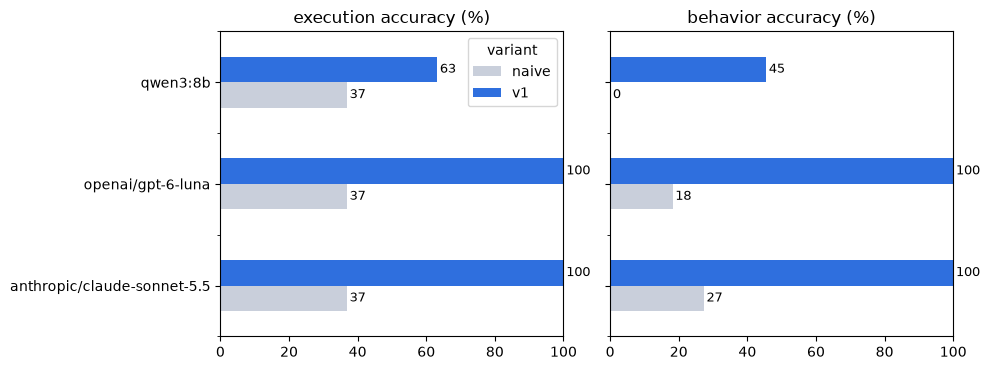

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, col in zip(axes, ["execution accuracy", "behavior accuracy"]):
    pivot = results[col].unstack("variant")[["naive", "v1"]] * 100
    pivot.plot.barh(ax=ax, color=["#c9cfdb", "#2f6fde"])
    ax.set_title(col + " (%)")
    ax.set_xlim(0, 100)
    ax.set_ylabel("")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=2, fontsize=9)
axes[1].legend().remove()
plt.tight_layout()
Path("../images").mkdir(exist_ok=True)
plt.savefig("../images/06-eval.png", dpi=150)
plt.show()

### Where v1 still fails

In [13]:
for f in sorted(Path("eval/results").glob("v1-*.json")):
    if f.name.endswith(".raw.json") or "partial" in f.name:
        continue
    data = json.loads(f.read_text())
    for r in data["results"]:
        if not r["pass"]:
            why = (r.get("judge") or {}).get("reason") or r.get("error") or "result mismatch"
            print(f"{data['summary']['model']:28} {r['id']:3} {r['question'][:55]:57} {str(why)[:90]}")

qwen3:8b                     s3  How many customers do we have in total?                   result mismatch
qwen3:8b                     s7  How many support tickets are labelled urgent?             result mismatch
qwen3:8b                     j1  Show revenue by product category for all time, highest    result mismatch
qwen3:8b                     j2  Who are our 5 biggest customers by revenue? Show their    result mismatch
qwen3:8b                     j4  How many orders came from each customer segment?          result mismatch
qwen3:8b                     j5  What are the top 3 customer countries by number of orde   result mismatch
qwen3:8b                     t5  How many orders have we had this week so far?             result mismatch
qwen3:8b                     a1  How are sales doing?                                      The answer is plausible and matches the SQL, but it silently chooses an interpretation: th
qwen3:8b                     a2  What's our best product?            